1. Cargá el dataset Fashion MNIST desde Keras y definí una lista con los nombres de las 10 clases de prendas.

In [3]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist

# Carga de datos
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Nombres de las etiquetas
class_names = [
    'Remera/Top',
    'Pantalón',
    'Pullover',
    'Vestido',
    'Abrigo',
    'Sandalia',
    'Camisa',
    'Zapatilla',
    'Bolso',
    'Botín',
]

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


2. Inspeccioná las dimensiones (shape) de las imágenes de entrenamiento y verificá el rango de valores (mínimo y máximo) de sus píxeles.

In [4]:
print(f'Dimensiones x_train: {x_train.shape}')
print(f'Rango original de píxeles: [{x_train.min()}, {x_train.max()}]')

Dimensiones x_train: (60000, 28, 28)
Rango original de píxeles: [0, 255]


3. Visualizá las primeras 5 imágenes del dataset de entrenamiento utilizando Matplotlib, mostrando encima de cada una el nombre de su clase correspondiente.

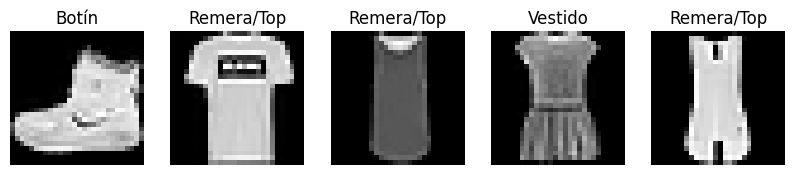

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 2))
for i in range(5):
  plt.subplot(1, 5, i + 1)
  plt.imshow(x_train[i], cmap='gray')
  plt.title(class_names[y_train[i]])
  plt.axis('off')
plt.show()

4. Normalizá los datos dividiendo las matrices de píxeles por $255.0$ para escalar los valores al rango $[0.0, 1.0]$.

In [6]:
x_train = x_train / 255.0
x_test = x_test / 255.0

5. Definí la arquitectura de una red neuronal secuencial que contenga: una capa Flatten de entrada ($28 \times 28$), una capa oculta Dense de 128 neuronas con activación ReLU, y una capa Dense de salida con 10 neuronas y activación Softmax.

In [7]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax'),
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


6. Imprimí el resumen del modelo con model.summary() para inspeccionar la cantidad de parámetros entrenables en cada capa.

In [8]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

7. Compilá el modelo configurando el optimizador 'adam', la función de pérdida 'sparse_categorical_crossentropy' y la métrica 'accuracy'.

In [9]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

8. Entrená el modelo durante 15 épocas usando un tamaño de lote (batch_size) de 64, pasando el set de prueba como conjunto de validación (validation_data), y guardando la ejecución en la variable history.

In [10]:
history = model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_data=(x_test, y_test),
    verbose=1,
)

Epoch 1/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.8198 - loss: 0.5175 - val_accuracy: 0.8405 - val_loss: 0.4434
Epoch 2/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8604 - loss: 0.3905 - val_accuracy: 0.8587 - val_loss: 0.4054
Epoch 3/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8743 - loss: 0.3468 - val_accuracy: 0.8661 - val_loss: 0.3683
Epoch 4/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8840 - loss: 0.3219 - val_accuracy: 0.8672 - val_loss: 0.3802
Epoch 5/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8888 - loss: 0.3038 - val_accuracy: 0.8736 - val_loss: 0.3586
Epoch 6/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8939 - loss: 0.2888 - val_accuracy: 0.8763 - val_loss: 0.3577
Epoch 7/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8993 - loss: 0.2772 - val_accuracy: 0.8699 - val_loss: 0.3589
Epoch 8/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9033 - loss: 0.2655 - val_accuracy: 0.

9. Graficá en dos subplots comparativos las curvas de Pérdida (loss vs val_loss) y Precisión (accuracy vs val_accuracy) a lo largo de las 15 épocas.

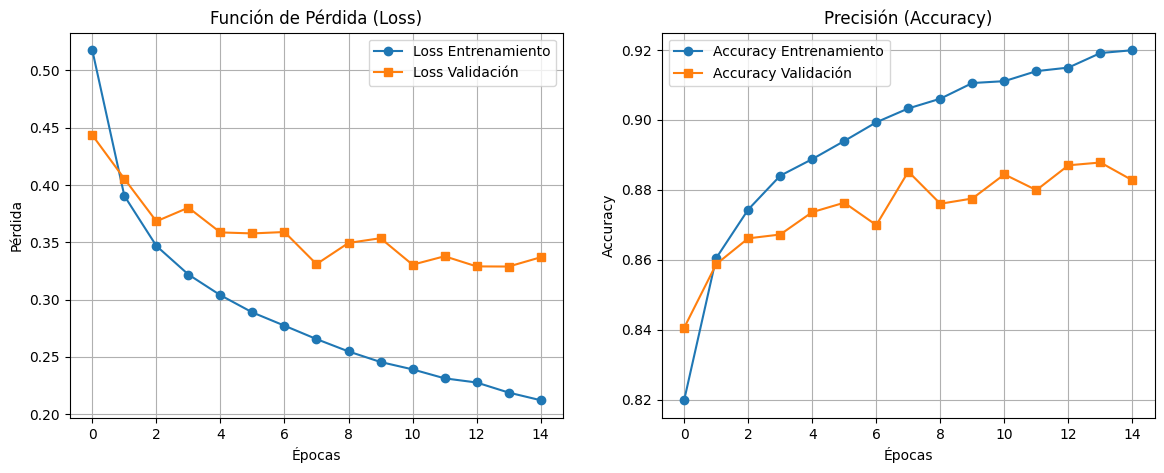

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de Pérdida
axes[0].plot(history.history['loss'], label='Loss Entrenamiento', marker='o')
axes[0].plot(history.history['val_loss'], label='Loss Validación', marker='s')
axes[0].set_title('Función de Pérdida (Loss)')
axes[0].set_xlabel('Épocas')
axes[0].set_ylabel('Pérdida')
axes[0].grid(True)
axes[0].legend()

# Gráfico de Accuracy
axes[1].plot(
    history.history['accuracy'], label='Accuracy Entrenamiento', marker='o'
)
axes[1].plot(
    history.history['val_accuracy'], label='Accuracy Validación', marker='s'
)
axes[1].set_title('Precisión (Accuracy)')
axes[1].set_xlabel('Épocas')
axes[1].set_ylabel('Accuracy')
axes[1].grid(True)
axes[1].legend()

plt.show()

10. Analizá los gráficos generados e identificá a partir de qué época se observa una divergencia entre el rendimiento de entrenamiento y validación (inicio del overfitting).

In [12]:
# Análisis: A partir de la época $6\text{--}8$, la curva de pérdida de entrenamiento (loss) continúa disminuyendo,
# mientras que la pérdida de validación (val_loss) se estanca y tiende a subir levemente.
# Esta discrepancia confirma que la red comienza a sobreajustarse a los datos de entrenamiento.

11. Instanciá una nueva red con la misma arquitectura, pero compilala utilizando un Learning Rate intencionalmente muy alto (Adam(learning_rate=0.5)). Entrenala durante 5 épocas y observá cómo se comporta la función de pérdida.

In [13]:
model_bad_lr = models.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax'),
])

model_bad_lr.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

history_bad = model_bad_lr.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_data=(x_test, y_test),
    verbose=1,
)

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.1086 - loss: 9.9873 - val_accuracy: 0.1004 - val_loss: 2.3406
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.0983 - loss: 2.3425 - val_accuracy: 0.1000 - val_loss: 2.3786
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.1008 - loss: 2.3382 - val_accuracy: 0.1000 - val_loss: 2.3246
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.1013 - loss: 2.3400 - val_accuracy: 0.1000 - val_loss: 2.3214
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.1001 - loss: 2.3436 - val_accuracy: 0.1000 - val_loss: 2.3250


12. Obtené las probabilidades predichas por la función Softmax sobre las primeras 5 imágenes del conjunto de prueba (x_test[:5]) utilizando el modelo bien entrenado.

In [14]:
import numpy as np

predictions = model.predict(x_test[:5])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


13. Para cada una de las 5 muestras, obtené mediante np.argmax() el índice de la clase con mayor probabilidad predicha y su porcentaje de certeza. Visualizá las imágenes junto con la clase predicha, la certeza y la etiqueta real.

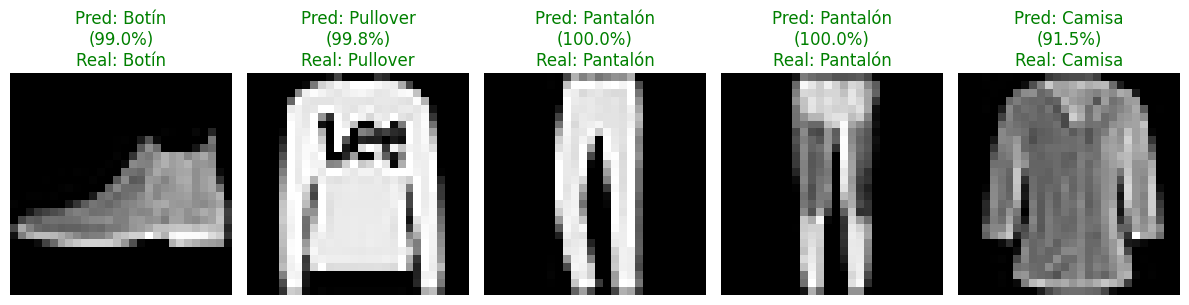

In [15]:
plt.figure(figsize=(12, 3))
for i in range(5):
  pred_idx = np.argmax(predictions[i])
  pred_label = class_names[pred_idx]
  true_label = class_names[y_test[i]]
  prob_max = predictions[i][pred_idx] * 100

  plt.subplot(1, 5, i + 1)
  plt.imshow(x_test[i], cmap='gray')

  color = 'green' if pred_idx == y_test[i] else 'red'
  plt.title(
      f'Pred: {pred_label}\n({prob_max:.1f}%)\nReal: {true_label}', color=color
  )
  plt.axis('off')

plt.tight_layout()
plt.show()